1070 cells, 4289 neighbour pairs
Overall (all neighbour pairs):
       pct_identical_all  pct_identical_active  pct_within2d_active  \
count            4289.00               4289.00              4289.00   
mean               85.46                 31.42                56.59   
std                 2.34                  7.62                 7.92   
min                74.25                  7.86                27.69   
25%                84.21                 26.12                51.33   
50%                85.53                 31.07                56.67   
75%                87.03                 36.61                62.14   
max                92.11                 56.31                80.56   

       jaccard_MHW_months  mean_abs_diff_days  pearson_r  
count             4289.00             4289.00    4289.00  
mean                 0.78                0.66       0.94  
std                  0.06                0.18       0.03  
min                  0.57                0.27       0.75  
2

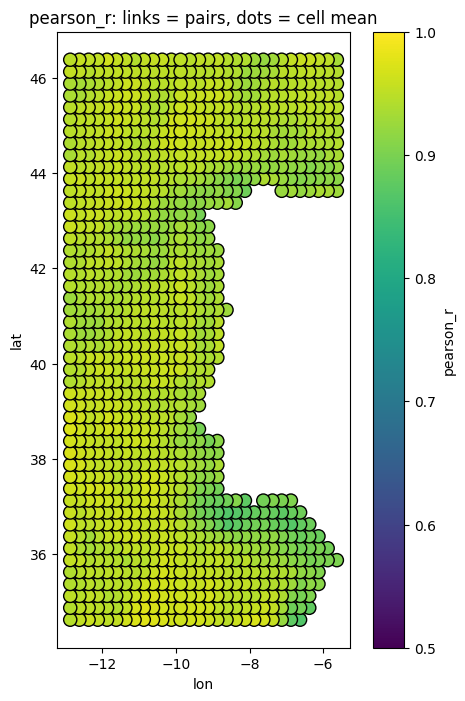

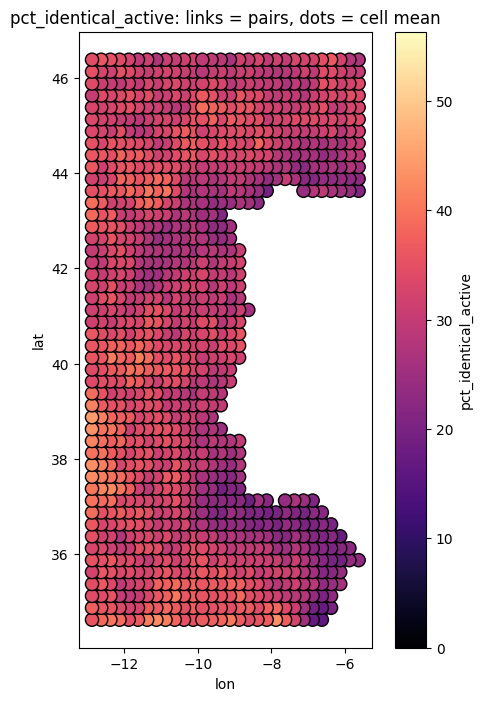

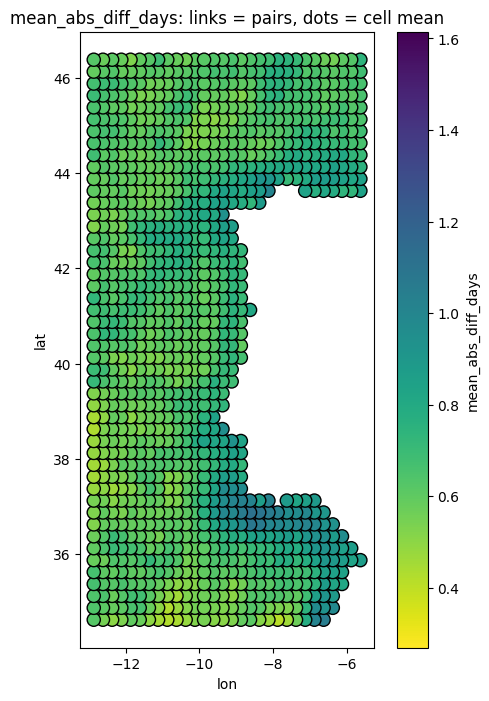

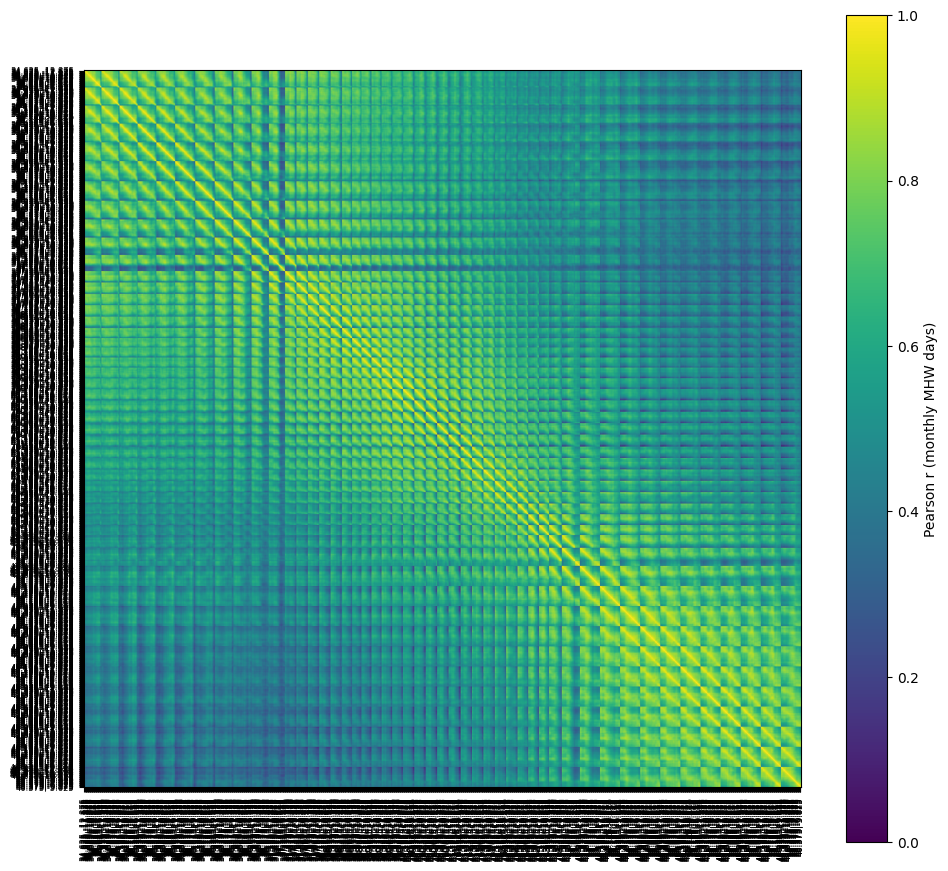

In [2]:
# %% [markdown]
# # MHW agreement: every grid cell vs its neighbours
# Paste each `# %%` block into a notebook cell (or run as-is in VS Code / Jupyter).

# %% ---------------------------------------------------------------- CONFIG
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CSV = "mhwDaysBigBox/MHW_monthly_table_oisst.19812025.IbPen_big_box.csv"
DAILY_CSV = None          # e.g. "mhw_daily.csv" with columns lat, lon, date, is_mhw  (None = skip)
RADIUS_KM = 40            # neighbours = cells within this distance (40 km ≈ 8 adjacent 0.25° cells)
MIN_NEIGHBOURS = 1        # if fewer within radius, add nearest cells until this many
MAX_FALLBACK_KM = 100     # ...but never further than this

# %% ---------------------------------------------------------------- HELPERS
def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 6371.0 * np.arcsin(np.sqrt(a))


def build_pairs(cells):
    """Unique neighbour pairs (i<j) based on RADIUS_KM / MIN_NEIGHBOURS."""
    lat, lon = cells["lat"].values, cells["lon"].values
    D = haversine_km(lat[:, None], lon[:, None], lat[None, :], lon[None, :])
    np.fill_diagonal(D, np.inf)
    pairs = set()
    for i in range(len(cells)):
        idx = np.where(D[i] <= RADIUS_KM)[0].tolist()
        if len(idx) < MIN_NEIGHBOURS:
            extra = [j for j in np.argsort(D[i]) if D[i, j] <= MAX_FALLBACK_KM and j not in idx]
            idx += extra[: MIN_NEIGHBOURS - len(idx)]
        pairs.update(tuple(sorted((i, j))) for j in idx)
    return sorted(pairs), D


def monthly_metrics(a, b):
    ok = a.notna() & b.notna()
    a, b = a[ok], b[ok]
    d = b - a
    act = (a > 0) | (b > 0)
    a_on, b_on = a > 0, b > 0
    return {
        "n_months": int(ok.sum()),
        "pct_identical_all": 100 * (d == 0).mean(),
        "pct_identical_active": 100 * (d[act] == 0).mean() if act.any() else np.nan,
        "pct_within2d_active": 100 * (d[act].abs() <= 2).mean() if act.any() else np.nan,
        "jaccard_MHW_months": (a_on & b_on).sum() / max((a_on | b_on).sum(), 1),
        "mean_abs_diff_days": d.abs().mean(),
        "pearson_r": a.corr(b),
        "spearman_r": a.corr(b, method="spearman"),
        "total_days_A": int(a.sum()),
        "total_days_B": int(b.sum()),
    }


def daily_metrics(a, b):
    ok = a.notna() & b.notna()
    a, b = a[ok].astype(bool), b[ok].astype(bool)
    both, either = (a & b).sum(), (a | b).sum()
    po = (a == b).mean()
    pe = a.mean() * b.mean() + (1 - a.mean()) * (1 - b.mean())
    return {
        "n_days": int(ok.sum()),
        "mhw_days_A": int(a.sum()),
        "mhw_days_B": int(b.sum()),
        "shared_mhw_days": int(both),
        "jaccard_days": both / either if either else np.nan,
        "cohen_kappa": (po - pe) / (1 - pe) if pe < 1 else np.nan,
        "pct_identical_days": 100 * po,
    }

# %% ---------------------------------------------------------------- LOAD + NEIGHBOURS
df = pd.read_csv(CSV)
df["lon"] = np.where(df["lon"] > 180, df["lon"] - 360, df["lon"])
df["cell"] = df["lat"].map("{:.3f}".format) + "," + df["lon"].map("{:.3f}".format)

cells = df.groupby(["cell", "zone", "lat", "lon"]).size().reset_index(name="n_months")
pairs, D = build_pairs(cells)
print(f"{len(cells)} cells, {len(pairs)} neighbour pairs")

isolated = [cells.cell[i] for i in range(len(cells)) if not any(i in p for p in pairs)]
if isolated:
    print("Cells with no neighbour:", isolated)

# %% ---------------------------------------------------------------- MONTHLY: ALL PAIRS
W = df.pivot_table(index=["year", "month"], columns="cell", values="mhw_days")

rows = []
for i, j in pairs:
    A, B = cells.iloc[i], cells.iloc[j]
    m = monthly_metrics(W[A.cell], W[B.cell])
    rows.append({"cell_A": A.cell, "zone_A": A.zone, "cell_B": B.cell, "zone_B": B.zone,
                 "dist_km": D[i, j], **m})
pairs_m = pd.DataFrame(rows)
pairs_m.to_csv("mhw_neighbour_pairs_monthly.csv", index=False)
pairs_m.round(2).sort_values("pearson_r")

# %% ---------------------------------------------------------------- MONTHLY: PER-CELL SUMMARY
long = pd.concat([
    pairs_m.rename(columns={"cell_A": "cell", "cell_B": "neighbour"}),
    pairs_m.rename(columns={"cell_B": "cell", "cell_A": "neighbour"}),
])
metric_cols = ["pct_identical_all", "pct_identical_active", "pct_within2d_active",
               "jaccard_MHW_months", "mean_abs_diff_days", "pearson_r"]
per_cell = (long.groupby("cell")
            .agg(n_neighbours=("neighbour", "size"), mean_dist_km=("dist_km", "mean"),
                 **{f"mean_{c}": (c, "mean") for c in metric_cols},
                 min_pearson_r=("pearson_r", "min"))
            .reset_index()
            .merge(cells[["cell", "zone", "lat", "lon"]], on="cell"))
per_cell.to_csv("mhw_neighbour_per_cell_monthly.csv", index=False)
per_cell.round(2).sort_values("mean_pearson_r")

# %% ---------------------------------------------------------------- OVERALL + BY DISTANCE
print("Overall (all neighbour pairs):")
print(pairs_m[metric_cols].describe().round(2))

bins = [0, 25, 30, 40, 60, 100]
pairs_m["dist_bin"] = pd.cut(pairs_m["dist_km"], bins)
pairs_m.groupby("dist_bin", observed=True)[metric_cols].mean().round(2)

# %% ---------------------------------------------------------------- MAPS
def map_metric(col, cmap="viridis", vmin=None, vmax=None, title=None):
    fig, ax = plt.subplots(figsize=(6, 8))
    norm = plt.Normalize(vmin if vmin is not None else pairs_m[col].min(),
                         vmax if vmax is not None else pairs_m[col].max())
    cm = plt.get_cmap(cmap)
    for _, r in pairs_m.iterrows():  # links coloured by pair metric
        la1, lo1 = map(float, r.cell_A.split(","))
        la2, lo2 = map(float, r.cell_B.split(","))
        ax.plot([lo1, lo2], [la1, la2], color=cm(norm(r[col])), lw=2.5, zorder=1)
    pc = per_cell.set_index("cell")
    sc = ax.scatter(pc.lon, pc.lat, c=pc[f"mean_{col}"], cmap=cmap, norm=norm,
                    s=90, edgecolor="k", zorder=2)
    plt.colorbar(sc, ax=ax, label=col)
    ax.set_xlabel("lon"); ax.set_ylabel("lat"); ax.set_aspect(1 / np.cos(np.radians(39.5)))
    ax.set_title(title or f"{col}: links = pairs, dots = cell mean")
    plt.show()

map_metric("pearson_r", vmin=0.5, vmax=1)
map_metric("pct_identical_active", cmap="magma", vmin=0)
map_metric("mean_abs_diff_days", cmap="viridis_r")

# %% ---------------------------------------------------------------- FULL CORRELATION MATRIX
order = cells.sort_values(["zone", "lat", "lon"]).cell
C = W[order].corr()
fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(C, vmin=0, vmax=1, cmap="viridis")
ax.set_xticks(range(len(order)), order, rotation=90, fontsize=6)
ax.set_yticks(range(len(order)), order, fontsize=6)
plt.colorbar(im, ax=ax, label="Pearson r (monthly MHW days)")
plt.tight_layout(); plt.show()

# %% ---------------------------------------------------------------- DAILY (optional: same DAYS?)
if DAILY_CSV:
    dd = pd.read_csv(DAILY_CSV, parse_dates=["date"])
    dd["lon"] = np.where(dd["lon"] > 180, dd["lon"] - 360, dd["lon"])
    dd["cell"] = dd["lat"].map("{:.3f}".format) + "," + dd["lon"].map("{:.3f}".format)
    dd["is_mhw"] = dd["is_mhw"].astype(str).str.lower().isin(["1", "true", "t", "yes"])
    WD = dd.pivot_table(index="date", columns="cell", values="is_mhw", aggfunc="max")

    rows = []
    for i, j in pairs:
        a, b = cells.cell[i], cells.cell[j]
        if a in WD and b in WD:
            rows.append({"cell_A": a, "cell_B": b, "dist_km": D[i, j],
                         **daily_metrics(WD[a], WD[b])})
    pairs_d = pd.DataFrame(rows)
    pairs_d.to_csv("mhw_neighbour_pairs_daily.csv", index=False)
    print(pairs_d[["jaccard_days", "cohen_kappa", "pct_identical_days"]].describe().round(3))
    display(pairs_d.round(3).sort_values("jaccard_days"))

In [3]:
df= pd.read_csv(CSV)

df.sample(10)

,zone,lat,lon,year,month,n_days,mhw_days,n_events,intensity_cum,intensity_max,cell_area_km2,intensity_mean,activity_degC_days_km2
447458,BigBox,44.625,349.875,1985,7,31,0,0,0.0,NaN,135.849481,NaN,0.0
44197,BigBox,35.375,347.875,1985,2,28,0,0,0.0,NaN,11.800945,NaN,0.0
255131,BigBox,40.125,347.875,2006,12,31,0,0,0.0,NaN,75.744358,NaN,0.0
183759,BigBox,37.875,349.875,1999,12,31,0,0,0.0,NaN,45.493381,NaN,0.0
424582,BigBox,44.125,354.125,1985,7,31,0,0,0.0,NaN,129.205753,NaN,0.0
467359,BigBox,44.875,351.625,2003,8,31,0,0,0.0,NaN,139.167498,NaN,0.0
212992,BigBox,38.875,347.125,1997,9,30,0,0,0.0,NaN,58.949695,NaN,0.0
8892,BigBox,34.625,351.125,2013,5,31,0,0,0.0,NaN,1.685913,NaN,0.0
32503,BigBox,35.125,349.125,1985,12,31,0,0,0.0,NaN,8.429407,NaN,0.0
69774,BigBox,35.625,352.875,1988,7,31,0,0,0.0,NaN,15.172258,NaN,0.0


In [10]:
olh = df[np.isclose(df['lat'], 36.875) & np.isclose(df['lon'], 352.125)].copy()

olh['date'] = pd.to_datetime(dict(year=df['year'], month=df['month'], day=1))
olh


,zone,lat,lon,year,month,n_days,mhw_days,n_events,intensity_cum,intensity_max,cell_area_km2,intensity_mean,activity_degC_days_km2,date
143640,BigBox,36.875,352.125,1981,9,30,0,0,0.000000,NaN,32.023209,NaN,0.000000,1981-09-01
143641,BigBox,36.875,352.125,1981,10,31,0,0,0.000000,NaN,32.023209,NaN,0.000000,1981-10-01
143642,BigBox,36.875,352.125,1981,11,30,0,0,0.000000,NaN,32.023209,NaN,0.000000,1981-11-01
143643,BigBox,36.875,352.125,1981,12,31,0,0,0.000000,NaN,32.023209,NaN,0.000000,1981-12-01
143644,BigBox,36.875,352.125,1982,1,31,0,0,0.000000,NaN,32.023209,NaN,0.000000,1982-01-01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
144167,BigBox,36.875,352.125,2025,8,31,15,2,33.556670,2.950573,32.023209,2.237111,1074.592290,2025-08-01
144168,BigBox,36.875,352.125,2025,9,30,0,0,0.000000,NaN,32.023209,NaN,0.000000,2025-09-01
144169,BigBox,36.875,352.125,2025,10,31,10,1,15.204403,1.677275,32.023209,1.520440,486.893771,2025-10-01
144170,BigBox,36.875,352.125,2025,11,30,8,0,11.539429,1.584017,32.023209,1.442429,369.529536,2025-11-01


<Axes: xlabel='date', ylabel='mhw_days'>

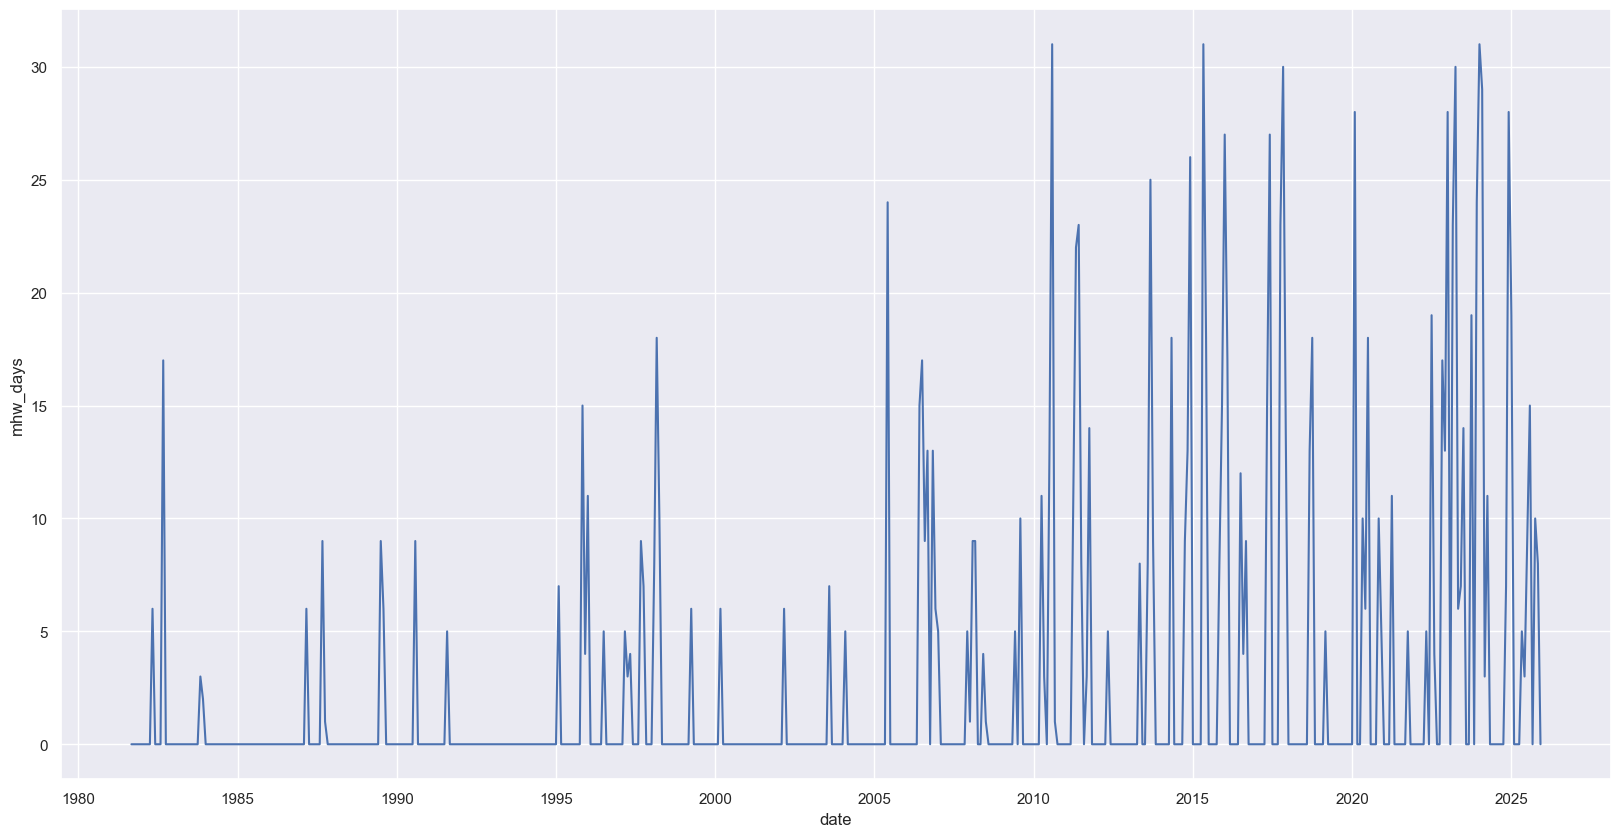

In [ ]:
import seaborn as sns
sns.set(rc = {'figure.figsize':(20,10)})
sns.lineplot(olh, x= 'date', y= 'mhw_days')

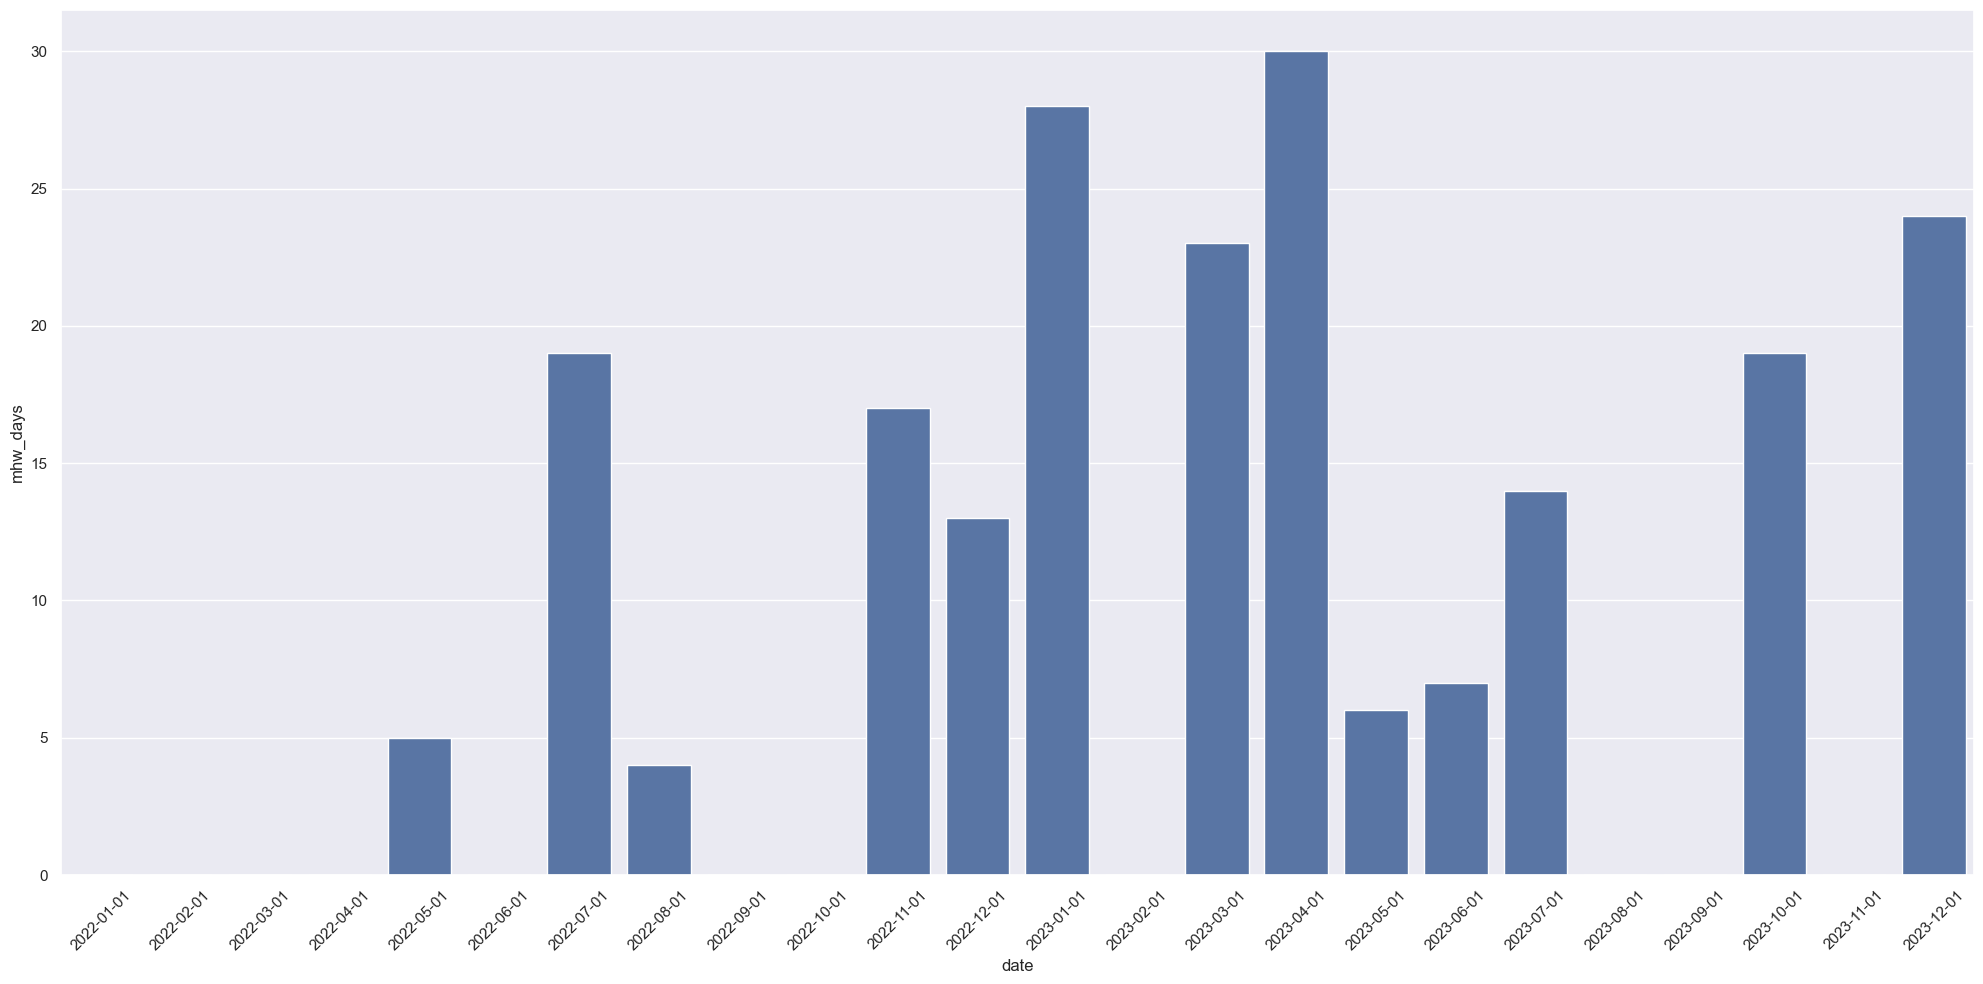

In [38]:
sns.barplot(olh[olh['year'].isin([2022,2023])], x= 'date', y= 'mhw_days')

plt.xticks(rotation=45)
plt.tight_layout()

<Axes: xlabel='date', ylabel='mhw_days'>

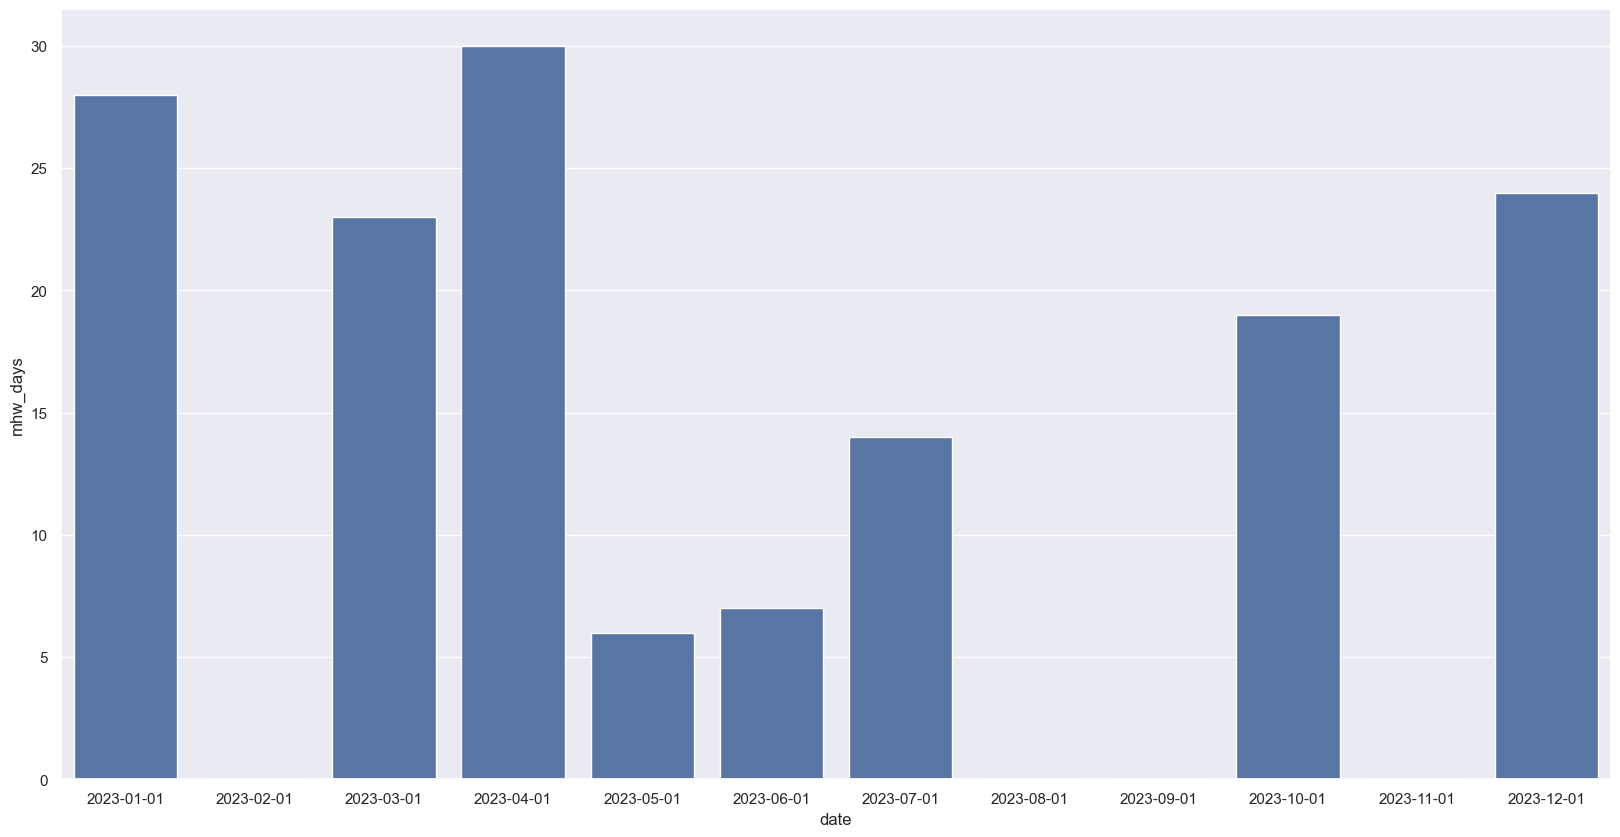

In [27]:
sns.barplot(olh[olh['year'].isin([2023])], x= 'date', y= 'mhw_days')

<Axes: xlabel='date', ylabel='intensity_mean'>

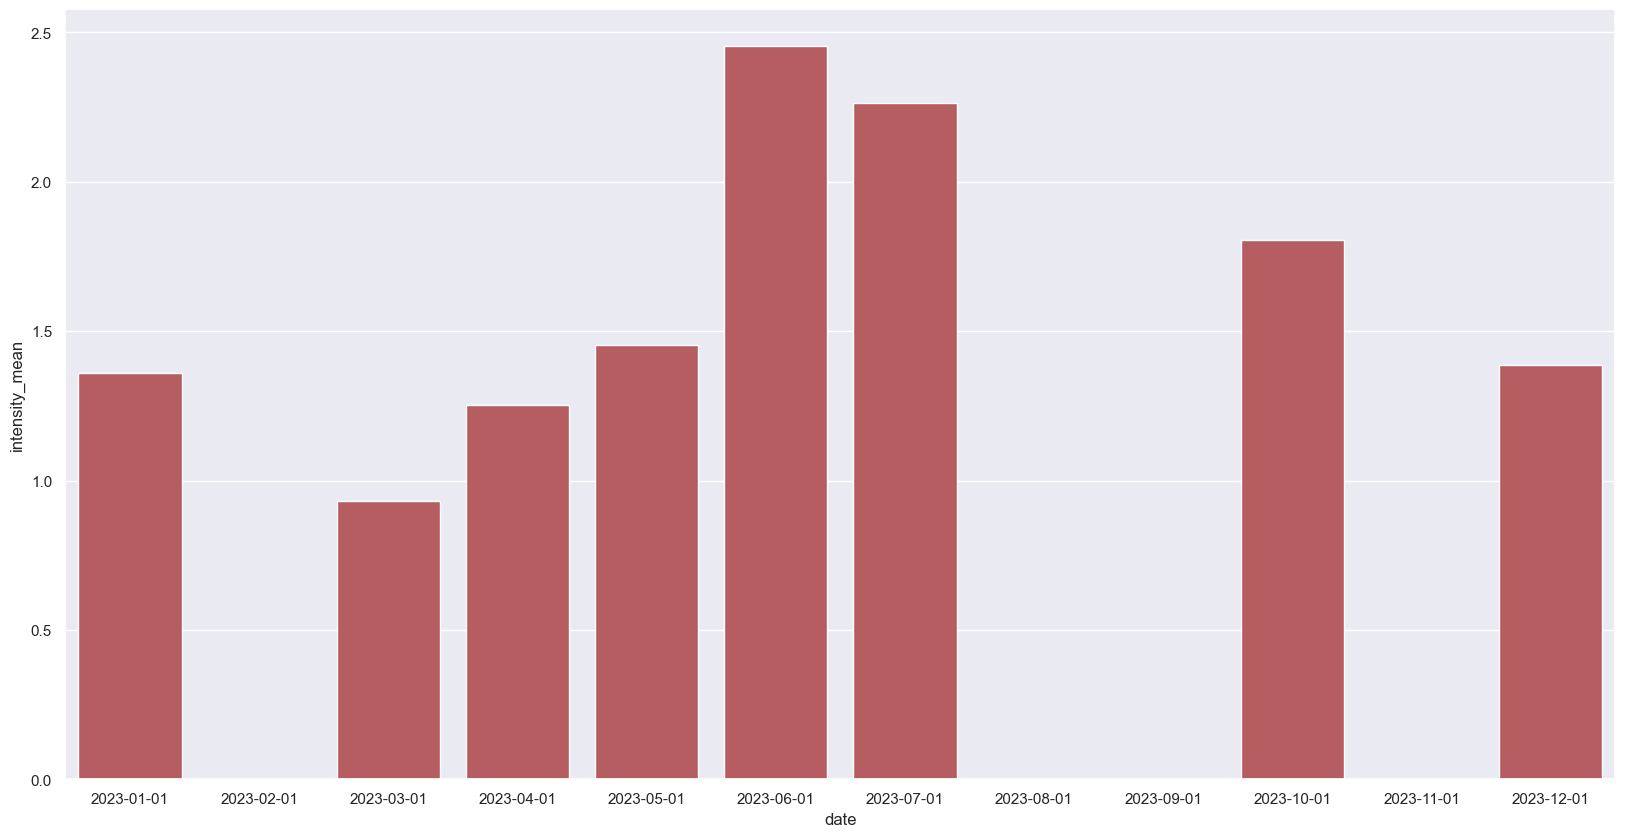

In [36]:
sns.barplot(olh[olh['year'].isin([2023])], x= 'date', y= 'intensity_mean', color= 'r')